# UN Comtrade: Extraction Validation & Exploratory Analysis

**Objective:** Evaluate the integrity, structure, and analytical usability of merchandise trade data retrieved from the UN Comtrade API.

The analysis uses Germany's monthly merchandise imports and exports for January–March 2023, followed by a controlled partner-level extraction for 2024.

The notebook examines source-data integrity, business grain, data quality, analytical transformations, and the considerations involved in expanding extraction scope.

## 1. Environment & Setup

The notebook uses the project's existing extraction client and configuration settings.

The initial analysis operates on locally cached JSON snapshots without contacting the API. The partner-level pilot is a separate, explicitly controlled live extraction.

**Requirements:** Install the project dependencies using `requirements.txt`. The monthly snapshot must exist in `data/raw/`; an authenticated UN Comtrade API key is required only for live extraction.

In [ ]:
from pathlib import Path
import hashlib
import json
import sys
from itertools import product
import pandas as pd

# Jupyter can start either at the project root or inside notebooks/.
working_dir = Path.cwd().resolve() # get current working directory
project_root = next(
    (path for path in (working_dir, *working_dir.parents)
     if (path / "src" / "extract.py").exists()),
    None,
) # checks for existence of src/extract.py in the current directory and its parents
if project_root is None:
    raise FileNotFoundError("Open this notebook from within the global-trade-flow-pipeline repository.")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
# initialize the client
from src.config import ComtradeSettings
from src.extract import ComtradeClient, TradeQuery

settings = ComtradeSettings.from_env()
client = ComtradeClient(settings)

print("Project:", project_root.name)
print("Raw directory:", settings.raw_dir)
print("Authenticated mode configured:", client.authenticated)
print("This cell made no network requests.")

Project: global-trade-flow-pipeline
Raw directory: C:\Users\ozgur\Desktop\Projects\global-trade-flow-pipeline\data\raw
Authenticated mode configured: True
This cell made no network requests.


## 2. Source Query Definition

The initial dataset covers Germany's merchandise imports and exports to/from the World aggregate for January–March 2023.

The request specifies monthly frequency, total commodities, both trade flows, and a maximum of 20 records.

A deterministic fingerprint identifies this exact request configuration, allowing the corresponding cached snapshot to be located. Changing any request-affecting parameter, including `max_records`, produces a different fingerprint.

In [ ]:
sample_query = TradeQuery(
    type_code="C",
    frequency_code="M",
    classification_code="HS",
    period="202301,202302,202303",
    reporter_code="276",    # Germany
    partner_code="0",       # World aggregate (not individual partners)
    commodity_code="TOTAL", # All commodities, one total
    flow_code="M,X",        # Imports and exports
    max_records=20, # Must match the original cached request
)

fingerprint = client.request_fingerprint(sample_query)
print("Fingerprint prefix:", fingerprint[:14])
print("This cell made no network requests.")

Fingerprint prefix: b4791db21a980b
This cell made no network requests.


## 3. Raw Data & Provenance Validation

The cached raw JSON payload is loaded directly from local storage to avoid unnecessary API calls.

Each snapshot is accompanied by a metadata sidecar containing its request fingerprint, retrieval timestamp, row count, and SHA-256 checksum.

The notebook checks the request identity, file integrity, and basic payload consistency before accepting a snapshot for analysis.

A missing or invalid snapshot causes the offline analysis to stop rather than silently downloading replacement data.

In [5]:
snapshot_paths = sorted(
    (
        path for path in settings.raw_dir.glob(f"comtrade_trade_{fingerprint}_*.json")
        if not path.name.endswith(".metadata.json") # find candidate JSON files that are not metadata
    ),
    reverse=True, # prioritize the newest files
)

snapshot = None
provenance = None
payload = None
for candidate in snapshot_paths:
    sidecar = candidate.with_name(f"{candidate.stem}.metadata.json") # build the 'sidecar' metadata filename
    if not sidecar.is_file(): # skip incomplete candidate
        continue
    try:
        payload_bytes = candidate.read_bytes()
        candidate_payload = json.loads(payload_bytes.decode("utf-8")) # get python objects by parsing the bytes converted into strings
        candidate_metadata = json.loads(sidecar.read_text(encoding="utf-8"))
    except (OSError, UnicodeError, json.JSONDecodeError):
        continue
    # verify cached file structure, fingerprint for API request, checksum for possible later corruptions, row counts
    if (
        isinstance(candidate_payload, dict)
        and isinstance(candidate_payload.get("data"), list)
        and isinstance(candidate_metadata, dict)
        and candidate_metadata.get("request_fingerprint") == fingerprint
        and candidate_metadata.get("payload_sha256") == hashlib.sha256(payload_bytes).hexdigest()
        and candidate_metadata.get("record_count") == len(candidate_payload["data"])
    ):
        snapshot, provenance, payload = candidate, candidate_metadata, candidate_payload
        break
# if no valid snapshot is found, raise error
if snapshot is None:
    raise FileNotFoundError(
        "No valid cached six-row snapshot found. Run the previous authenticated "
        "smoke-test query with max_records=20 once, then rerun this notebook. "
        "This notebook deliberately did not contact the API."
    )

print("Loaded:", snapshot.name)
print("Rows:", len(payload["data"]))
print("Retrieved UTC:", provenance.get("retrieved_at_utc"))
print("Possible truncation:", provenance.get("possibly_truncated"))
print("API attempts used by this notebook: 0")

Loaded: comtrade_trade_b4791db21a980b2209840e393ab881fc43d516b78d2dad5ac669ea7e9a206339_20261102T145313856109Z.json
Rows: 6
Retrieved UTC: 2026-11-02T14:53:13.856652Z
Possible truncation: False
API attempts used by this notebook: 0


## 4. Data Structure & Grain

The raw JSON observations are normalized into a Pandas DataFrame, with selected columns converted to appropriate data types.

For this specific dataset, the reporting country, trading partner (`World`), and commodity category (`TOTAL`) are fixed.

The resulting candidate business grain is:

**Reporter × Period × Trade Flow**

This grain applies only to the current aggregate-level dataset. More detailed partner- or product-level observations require additional dimensions to uniquely identify records.

In [ ]:
trade_df = pd.json_normalize(payload["data"]).copy() # convert JSON into tabular data based on response shape
trade_df["period"] = trade_df["period"].astype(str) # standardize period
trade_df["flowCode"] = trade_df["flowCode"].astype(str) # standardize flow code (imports, exports)
trade_df["primaryValue"] = pd.to_numeric(trade_df["primaryValue"], errors="coerce") # standardize value, if conversion fails, show NaN

preview_columns = [
    "reporterCode", "reporterDesc", "period", "flowCode", "partnerCode",
    "cmdCode", "primaryValue",
]
print("Shape:", trade_df.shape)
display(trade_df[preview_columns].sort_values(["period", "flowCode"])) # view selected columns, in a sorted way

Shape: (6, 47)


,reporterCode,reporterDesc,period,flowCode,partnerCode,cmdCode,primaryValue
0,276,Germany,202301,M,0,TOTAL,1.286682e+11
1,276,Germany,202301,X,0,TOTAL,1.395805e+11
3,276,Germany,202302,M,0,TOTAL,1.229787e+11
2,276,Germany,202302,X,0,TOTAL,1.422409e+11
4,276,Germany,202303,M,0,TOTAL,1.387956e+11
5,276,Germany,202303,X,0,TOTAL,1.634882e+11


## 5. Data Quality Validation

The dataset is evaluated against three core quality dimensions:

- **Uniqueness:** No duplicate observations under the candidate business grain.
- **Coverage:** All six expected month–flow combinations are present, with no unexpected combinations.
- **Validity:** Primary trade values are available and the extraction contains no reported truncation warnings.

These checks verify the defined sample scope, rather than establishing completeness for all possible UN Comtrade observations.

In [ ]:
grain = ["reporterCode", "period", "flowCode"] # this is the query grain
# in the example we are working, every row should represent a country, a month and the type of trade flow
expected = set(product(["202301", "202302", "202303"], ["M", "X"])) # generate the cartesian product of the expected column values and store in set
actual = set(trade_df[["period", "flowCode"]].itertuples(index=False, name=None)) # get the set of actual values

quality_results = {
    "duplicate_keys": int(trade_df.duplicated(subset=grain).sum()), # check for repeated records under selected grain
    "missing_expected_combinations": sorted(expected - actual), # combinations expected but didn't receive
    "unexpected_combinations": sorted(actual - expected), # combinations received that aren't expected
    "missing_primary_values": int(trade_df["primaryValue"].isna().sum()), # missing trade values
    "possible_truncation": bool(provenance.get("possibly_truncated", True)), # check for possible truncation, if metadata field is missing, defaults to True
}
display(pd.DataFrame([quality_results]))
# assert checks to make sure execution doesn't continue in case of a failing condition
assert quality_results["duplicate_keys"] == 0
assert not quality_results["missing_expected_combinations"]
assert not quality_results["unexpected_combinations"]
assert quality_results["missing_primary_values"] == 0
assert not quality_results["possible_truncation"]
print("All scoped six-row checks passed.")

,duplicate_keys,missing_expected_combinations,unexpected_combinations,missing_primary_values,possible_truncation
0,0,[],[],0,False


All scoped six-row checks passed.


## 6. Analytical Transformation

The validated observations are transformed into a monthly analytical summary using Pandas.

Import and export records are pivoted into separate columns, changing the output grain from reporter–period–flow to reporter–period.

Monthly merchandise trade balances are then calculated as:

**Trade Balance = Exports − Imports**

Trade values are presented in USD billions for readability, while the underlying source values remain unchanged.

In [10]:
# we are transforming the data to be of better use for analysis
monthly = ( # create a pivot table to bring exports and imports together for a single period & country
    trade_df.pivot(
        index=["reporterCode", "period"], # what identifies each output
        columns="flowCode", # which field becomes separate columns
        values="primaryValue", # which numbers will populate the separated columns
    )
    .rename(columns={"M": "imports_usd", "X": "exports_usd"}) # give column names
    .reset_index()
)
monthly.columns.name = None
monthly["trade_balance_usd"] = monthly["exports_usd"] - monthly["imports_usd"] # create the trade balance column
# convert values to billions for better visibility
monthly_billions = monthly.assign(
    imports_usd=monthly["imports_usd"] / 1e9,
    exports_usd=monthly["exports_usd"] / 1e9,
    trade_balance_usd=monthly["trade_balance_usd"] / 1e9,
)
print("USD billions:")
display(monthly_billions.round(2))

USD billions:


,reporterCode,period,imports_usd,exports_usd,trade_balance_usd
0,276,202301,128.67,139.58,10.91
1,276,202302,122.98,142.24,19.26
2,276,202303,138.80,163.49,24.69


## 7. Trade Visualization

Monthly import and export values are visualized using Matplotlib.

The chart illustrates the relationship between Germany's merchandise imports and exports during the three-month sample period. The short observation window is intended to demonstrate the analytical workflow rather than support conclusions about long-term trade trends.

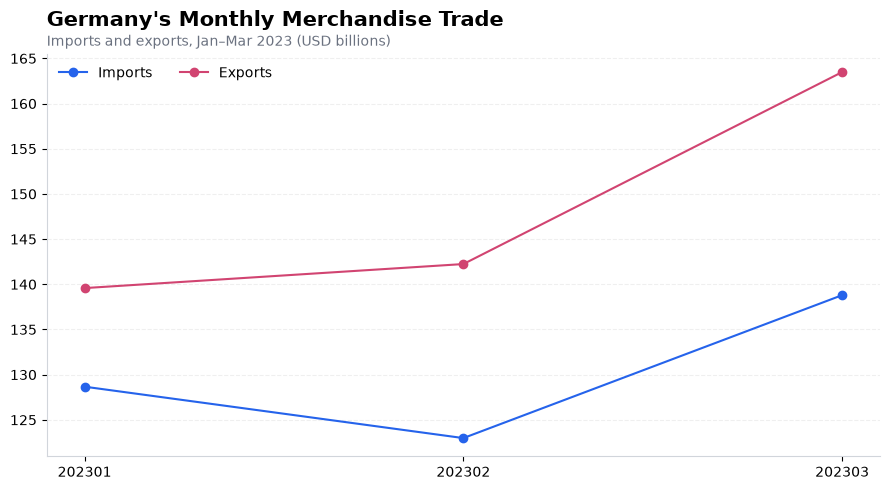

In [27]:
import matplotlib.pyplot as plt

plot_df = monthly_billions.sort_values("period") # make sure data is chronologically ordered
fig, ax = plt.subplots(figsize=(9, 5)) # create the figure with width and height
ax.plot(plot_df["period"], plot_df["imports_usd"], marker="o", label="Imports", color="#2563eb") # plot imports
ax.plot(plot_df["period"], plot_df["exports_usd"], marker="o", label="Exports", color="#d14471") # plot exports
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#d1d5db")
ax.spines["bottom"].set_color("#d1d5db")
ax.set_title("Germany's Monthly Merchandise Trade", loc="left", fontsize=15, fontweight="bold", pad=20)
fig.text(0, 1.02, "Imports and exports, Jan–Mar 2023 (USD billions)", transform=ax.transAxes, fontsize=10, color="#6b7280", ha="left")
ax.grid(axis="y", alpha=0.2, linestyle="--") # add gridlines
ax.legend(frameon=False, ncol=2, loc="upper left") # display legend
plt.tight_layout() # adjust spacing to reduce overlapping
plt.show() # display the chart, common practice to call it

## 8. Partner-Level Extraction Pilot

A controlled extraction extends the analysis to Germany's **annual merchandise exports in 2024**, using five explicitly selected trading-partner codes:

| Partner | UN Comtrade code |
|---|---|
| World | 0 |
| United States | 842 |
| China | 156 |
| France | 251 |
| United Kingdom | 826 |

The pilot uses total commodities (`TOTAL`) and a maximum response size of 2,000 records.

The analysis examines returned partner coverage, duplicate partner codes, missing trade values, cache reuse, and potential truncation.

**Aggregation consideration:** The World record represents an aggregate and must not be summed together with individual partner observations. The pilot therefore assesses partner-level structure without assuming that all returned rows are additive.

The live request is explicitly controlled to prevent unintentional API calls. Source limits and query options are documented in the [UN Comtrade API documentation](https://uncomtrade.org/docs/data/) and [subscription limits](https://uncomtrade.org/docs/subscriptions/).


In [ ]:
# IMPORTANT: Changing this to True opts in to a live authenticated call.
RUN_LIVE_PILOT = False

pilot_query = TradeQuery(
    type_code="C",
    frequency_code="A",
    classification_code="HS",
    period="2024",
    reporter_code="276",
    partner_code="0,842,156,251,826",  # Partner breakdown; may include the World total
    commodity_code="TOTAL",
    flow_code="X",
    max_records=2000,
)

if RUN_LIVE_PILOT:
    if not client.authenticated:
        raise RuntimeError("Authenticated API key not configured; refusing live pilot.")

    pilot_result = client.download_trade_data(pilot_query)
    pilot_df = pd.json_normalize(pilot_result.payload["data"])

    expected_partners = {0, 842, 156, 251, 826}
    actual_partners = set(pilot_df["partnerCode"].astype(int))

    print("Missing requested partners:", expected_partners - actual_partners)
    print("Unexpected partners:", actual_partners - expected_partners)

    if pilot_df.empty:
        raise ValueError("The pilot returned no records.")

    print("Rows:", pilot_result.record_count)
    print("From cache:", pilot_result.from_cache)
    print("Possibly truncated:", pilot_result.possibly_truncated)
    print("Warning codes:", pilot_result.warning_codes)
    print("Unique partners:", pilot_df["partnerCode"].nunique())

    display(pilot_df[["partnerCode", "partnerDesc", "primaryValue"]].head(15))

    # Additional data-quality diagnostics
    print("World aggregate rows:", pilot_df["partnerCode"].eq(0).sum())
    print("Duplicate partner codes:", pilot_df.duplicated(subset=["partnerCode"]).sum())
    print("Missing trade values:", pd.to_numeric(pilot_df["primaryValue"], errors="coerce").isna().sum())
    print("Raw snapshot:", pilot_result.payload_path)

    if pilot_result.possibly_truncated:
        print("STOP: inspect query scope/partitioning before using data analytically.")
else:
    print("Live pilot disabled — no API request made.")

Missing requested partners: set()
Unexpected partners: set()
Rows: 5
From cache: True
Possibly truncated: False
Warning codes: ()
Unique partners: 5


,partnerCode,partnerDesc,primaryValue
0,0,World,1.684875e+12
1,156,China,9.773405e+10
2,251,France,1.250458e+11
3,826,United Kingdom,8.743307e+10
4,842,USA,1.755690e+11


World aggregate rows: 1
Duplicate partner codes: 0
Missing trade values: 0
Raw snapshot: C:\Users\ozgur\Desktop\Projects\global-trade-flow-pipeline\data\raw\comtrade_trade_0739d3c22924c9b62d615b7b6c195829becf85bbd83e807b17becab9b7d7cf88_20261103T194046599539Z.json


## 9. Conclusion

This notebook validated the extraction and basic analytical usability of UN Comtrade merchandise trade data.

### Key Findings

- **Snapshot integrity:** Cached JSON files were located and checked using request fingerprints, metadata, and SHA-256 checksums.
- **Data quality:** The monthly sample contained 6 records across 47 attributes, with all expected combinations present and no duplicate candidate keys or missing trade values.
- **Analytical transformation:** Monthly imports and exports were converted into trade balance summaries, showing a German merchandise trade surplus in all three observed months.
- **Partner-level pilot:** All 5 selected partners were returned, with no duplicate partner codes, missing trade values, or truncation warnings.
- **Cache reuse:** The partner-level pilot demonstrated successful reuse of a previously saved snapshot.

### Limitations

These findings apply to the tested queries and do not establish completeness for larger datasets. Aggregate records require careful treatment to avoid double-counting, and more detailed extractions need additional business-key and coverage validation.

### Final Assessment

The extraction workflow successfully supports reproducible snapshot loading, integrity checks, basic data-quality validation, and exploratory analysis, providing a foundation for larger datasets and subsequent DuckDB modeling.